# Opensees - Tutorial

### <span style="color: #58a6ff;">RULES</span>
---

#### Python Syntax: The Asterisk (`*args` / Unpacking)

The `*` symbol allows passing multiple arguments or unpacking a list into a function:

* **Direct sequence:** Pass numbers separated by commas:
  `ops.eleLoad('-ele', 1, 2, 3, '-type', '-beamUniform', -20.0)`

* **List unpacking:** Use `*` to unpack a Python list into arguments:
  ```python
  beam_elements = [1, 2, 3]
  ops.eleLoad("-ele", *beam_elements, "-type", "-beamUniform", -20.0)

### <span style="color: #58a6ff;">MODEL & NODES & BOUNDARY CONDITIONS</span>
---

#### <span style="color: #58a6ff;">Model</span>

- `basic` – standard model builder type
- `-ndm` (Number of Dimensions): `2` -> 2D (plane), `3` -> 3D
- `-ndf` (Number of Degrees of Freedom per node)

Frame 2D / Beam 2D (X, Y, RZ):
`ops.model('basic', '-ndm', 2, '-ndf', 3)`

Truss 2D (X, Y):
`ops.model('basic', '-ndm', 2, '-ndf', 2)`

Frame 3D (X, Y, Z, RX, RY, RZ):
`ops.model('basic', '-ndm', 3, '-ndf', 6)`

Truss 3D (X, Y, Z):
`ops.model('basic', '-ndm', 3, '-ndf', 3)`

In [3]:
import openseespy.opensees as ops

# FRAME 2D / BEAM 2D (X,Y,RZ):
ops.model('basic', '-ndm', 2, '-ndf', 3)

# TRUSS 2D (X,Y):
ops.model('basic', '-ndm', 2, '-ndf', 2)

# FRAME 3D (X,Y,Z,RX,RY,RZ):
ops.model('basic', '-ndm', 3, '-ndf', 6)

# TRUSS 3D (X,Y,Z):
ops.model('basic', '-ndm', 3, '-ndf', 3)

#### <span style="color: #58a6ff;">Nodes</span>

`nodeTag` – every node needs a unique number/tag

Syntax:
- 2D: `ops.node(nodeTag, x, y)`
- 3D: `ops.node(nodeTag, x, y, z)`

```python
ops.node(1, 0.0, 0.0)
ops.node(2, 5.0, 0.0)
ops.node(3, 10.0, 5.0)

#### <span style="color: #58a6ff;">Boundary Conditions & External Supports</span>

* Syntax: `ops.fix(node_tag, *dofs)`

* `1` – Fixed (Restrained)
* `0` – Free (Unrestrained)

For 2D model (`ndm=2`, `ndf=3`) -> `ops.fix(node_tag, UX, UY, RZ)`

**Typical Support Types (2D):**

* **Fixed:** `ops.fix(node_tag, 1, 1, 1)`
* **Pinned / Hinge:** `ops.fix(node_tag, 1, 1, 0)`
* **Roller X (Free X, Fixed Y):** `ops.fix(node_tag, 0, 1, 0)`
* **Roller Y (Fixed X, Free Y):** `ops.fix(node_tag, 1, 0, 0)`
* **Slider / Guided Roller:** `ops.fix(node_tag, 0, 1, 1)`

In [ ]:
# Fixed:
ops.fix(node_tag, 1, 1, 1)

# Pinned / Hinge:
ops.fix(node_tag, 1, 1, 0)

# Roller X (Free X, Fixed Y):
ops.fix(node_tag, 0, 1, 0)

# Roller Y (Fixed X, Free Y):
ops.fix(node_tag, 1, 0, 0)

# Slider / Guided Roller:
ops.fix(node_tag, 0, 1, 1)

### <span style="color: #58a6ff;">MATERIAL & SECTION</span>
---

#### <span style="color: #58a6ff;">UniaxialMaterial</span>

* Syntax: `ops.uniaxialMaterial(matType, matTag, *matArgs)`

**Most Common Types:**
* **Elastic (Pure linear elastic):**
  `ops.uniaxialMaterial('Elastic', matTag, E)`
  * `E` = Young's modulus [$MPa$]

* **Steel01 (Bilinear kinematic hardening):**
  `ops.uniaxialMaterial('Steel01', matTag, Fy, E0, b)`
  * `Fy` = yield strength $f_{yd} = f_{yk} / \gamma_s$ (e.g. for B500: $500 / 1.15 \approx 435.0$ MPa)
  * `E0` = initial elastic modulus $E_s$ (e.g. $200000.0$ MPa)
  * `b` = strain-hardening ratio $E_{post-yield} / E_0$ (e.g. `0.01` $\rightarrow 1\%$ slope after yield)

* **Concrete01 (Uniaxial Kent-Scott-Park zero-tensile concrete):**
  `ops.uniaxialMaterial('Concrete01', matTag, fpc, epsc0, fpcu, epsU)`
  * `fpc` = compressive strength (negative value, e.g. $-f_{cd} = -20.0$ MPa)
  * `epsc0` = strain at peak strength (e.g. $-\varepsilon_{c2} = -0.0020$)
  * `fpcu` = crushing strength (e.g. $-0.2 \cdot f_{cd} = -4.0$ MPa)
  * `epsU` = ultimate crushing strain (e.g. $-\varepsilon_{cu2} = -0.0035$)

* **Concrete02 (Tensile strength & linear tension stiffening):**
  `ops.uniaxialMaterial('Concrete02', matTag, fpc, epsc0, fpcu, epsU, lambda, ft, Ets)`
  * Compression parameters: `fpc`, `epsc0`, `fpcu`, `epsU` (same as Concrete01, negative values)
  * `lambda` = ratio between unloading slope at `epsU` and initial slope $E_c$ (typically `0.1`)
  * `ft` = tensile strength (positive value, in EC2 $f_{ctm}$, e.g. `2.9` MPa)
  * `Ets` = tension softening modulus ($E_{ts} = f_t / \varepsilon_{tu}$, e.g. $\approx 0.05 \cdot E_c \approx 1600.0$ MPa)


**Examples:**

* **Elastic (Linear):**
  `ops.uniaxialMaterial('Elastic', 1, 210000.0)`  # Structural steel S235/S355 elastic

* **Steel01 (Eurocode B500B):**
  `ops.uniaxialMaterial('Steel01', 2, 435.0, 200000.0, 0.01)`  # Reinforcing steel (Fyd=435 MPa, Es=200 GPa, b=1%)

* **Concrete01 (Eurocode C30/37):**
  `ops.uniaxialMaterial('Concrete01', 3, -20.0, -0.0020, -0.2 * 20.0, -0.0035)`  # Unconfined concrete

* **Concrete02 (Eurocode C30/37 – With tension stiffening):**
  `ops.uniaxialMaterial('Concrete02', 4, -20.0, -0.0020, -0.2 * 20.0, -0.0035, 0.1, 2.9, 1600.0)`

#### <span style="color: #58a6ff;">Section</span>

Defines cross-section force-deformation behavior ($N-M-V$) for frame elements.

* Syntax: `ops.section(secType, secTag, *secArgs)`

**Most Common Types:**

* **Elastic (Pure linear elastic cross-section):**
  * 2D Frame: `ops.section('Elastic', secTag, E, A, Iz)`
  * 3D Frame: `ops.section('Elastic', secTag, E, A, Iz, Iy, G, J)`
  * `E` = Young's modulus [$MPa$]
  * `A` = cross-sectional area [$mm^2$]
  * `Iz`, `Iy` = moments of inertia [$mm^4$]
  * `G` = shear modulus [$MPa$], `J` = torsional constant [$mm^4$]

* **Fiber (Discretized non-linear RC / steel cross-section):**
  Constructs a cross-section composed of fibers, where each fiber has an area, $(y, z)$ coordinate, and its own `uniaxialMaterial` (e.g. core concrete, cover concrete, rebar steel).


**Fiber Section Syntax Breakdown (2D Rectangular RC Section Example):**

```python
# 1. Open fiber section definition
ops.section("Fiber", secTag)

# 2. Add concrete patch (quadrilateral / rectangular region)
# ops.patch('rect', matTag, numSubdivY, numSubdivZ, yI, zI, yK, zK)
ops.patch("rect", concMatTag, 10, 1, -h / 2, -b / 2, h / 2, b / 2)

# 3. Add reinforcement layers
# ops.layer('straight', matTag, numRebars, rebarArea, yStart, zStart, yEnd, zEnd)
ops.layer("straight", steelMatTag, 3, 314.0, -h / 2 + c, 0.0, -h / 2 + c, 0.0)  # Bottom layer (3x fi 20)
ops.layer("straight", steelMatTag, 2, 201.0,  h / 2 - c, 0.0,  h / 2 - c, 0.0)  # Top layer (2x fi 16)

### <span style="color: #58a6ff;">GEOM TRANSFORMATIONS  &  ELEMENTS</span>
---

#### <span style="color: #58a6ff;">Geometric Transformation</span>

Correlates local member coordinate system with the global coordinate system.

* Syntax: `ops.geomTransf(type, transf_tag)`

* Types:
  * `'Linear'` – Linear 1st order analysis (small displacements/rotations)
  * `'PDelta'` – Second-order geometric effects ($P-\Delta$)
  * `'Corotational'` – Large displacements and large rotations

* Examples:
  * `ops.geomTransf('Linear', 1)`
  * `ops.geomTransf('PDelta', 1)`
  * `ops.geomTransf('Corotational', 1)`

#### <span style="color: #58a6ff;">ElasticBeamColumn</span>

* Syntax: `ops.element('elasticBeamColumn', eleTag, iNode, jNode, A, E, I, transfTag)`

**Parameters (Units: N, mm, MPa, t/mm):**
* `eleTag` = `1`, `2`, `3` (unique element tag)
* `iNode` = start node tag
* `jNode` = end node tag
* `A` = cross-section area [$mm^2$]
* `E` = Young's modulus [$MPa$]
* `I` = second moment of inertia [$mm^4$]
* `transfTag` = geometric transformation tag

**Example:**
`ops.element('elasticBeamColumn', 1, 1, 2, A, E, I, 1)`

---

**With Mass Option (Dynamic / Modal):**

* Syntax: `ops.element('elasticBeamColumn', eleTag, iNode, jNode, A, E, I, transfTag, '-mass', Mass, massType)`

**Mass Parameters:**
* `'-mass'` = flag informing mass definition
* `Mass` = mass per unit length [$t/mm$]
* `massType`:
  * `'-lMass'` = lumped mass matrix (default)
  * `'-cMass'` = consistent mass matrix

**Example:**
`ops.element('elasticBeamColumn', 1, 1, 2, A, E, I, 1, '-mass', 0.0422e-3, '-cMass')`

#### <span style="color: #58a6ff;">Truss</span>

* Syntax: `ops.element('Truss', eleTag, iNode, jNode, A, matTag)`

**Parameters (Units: N, mm, MPa, t/mm):**
* `eleTag` = unique element tag (e.g. `1`, `2`, `3`)
* `iNode` = start node tag
* `jNode` = end node tag
* `A` = cross-section area [$mm^2$]
* `matTag` = tag of previously defined `uniaxialMaterial`

**Example:**
* `ops.element('Truss', 1, 1, 2, A, matTag)`

---

**With Mass & Damping Options (Dynamic / Modal):**

* Syntax: `ops.element('Truss', eleTag, iNode, jNode, A, matTag, '-rho', rho, '-cMass', cFlag, '-doRayleigh', rFlag)`

**Optional Parameters:**
* `'-rho', rho` = mass per unit length [$t/mm$] (default = `0.0`)
* `'-cMass', cFlag` = mass matrix type:
  * `cFlag = 0` $\rightarrow$ lumped mass matrix (default)
  * `cFlag = 1` $\rightarrow$ consistent mass matrix
* `'-doRayleigh', rFlag` = Rayleigh damping inclusion:
  * `rFlag = 0` $\rightarrow$ no Rayleigh damping (default)
  * `rFlag = 1` $\rightarrow$ include Rayleigh damping

**Example:**
* `ops.element('Truss', 1, 1, 2, A, matTag, '-rho', 0.0422e-3, '-cMass', 1, '-doRayleigh', 1)`

### <span style="color: #58a6ff;">TIME_SERRIES & PATTERNS</span>
---

#### <span style="color: #58a6ff;">TimeSeries</span>

* Syntax: `ops.timeSeries(tsType, tsTag, *tsArgs)`

**Types:**
* `'Linear'` – load factor increases linearly (standard for static analysis)
* `'Constant'` – constant load factor ($= 1.0$)
* `'Path'` – user-defined time series from a file/list (e.g. earthquake record)

**Examples:**
* `ops.timeSeries('Linear', 1)`
* `ops.timeSeries('Constant', 1, '-factor', 1.0)`

#### <span style="color: #58a6ff;">Pattern</span>

* Syntax: `ops.pattern(patternType, patternTag, *patternArgs)`

**Types:**
* `'Plain'` – standard pattern for static and nodal/element loads
* `'UniformExcitation'` – uniform ground motion excitation (dynamic)

**Examples:**
* `ops.pattern('Plain', 1, 1)`
* `ops.pattern('UniformExcitation', 2, 1, '-accel', 1)`  # dir=1 (X), dir=2 (Y)

### <span style="color: #58a6ff;">LOADING (nodal, DLD, Point load) </span>
---

#### <span style="color: #58a6ff;">Nodal Load</span>

* Syntax: `ops.load(nodeTag, Fx, Fy, Mz)`

**Parameters (Units: N, mm):**
* `nodeTag` = target node tag
* `Fx` = horizontal point load [$N$]
* `Fy` = vertical point load [$N$] (negative = downwards)
* `Mz` = bending moment [$N \cdot mm$]

**Examples:**
* `ops.load(2, 0.0, -10000.0, 0.0)`  # Fy = -10 kN at Node 2
* `ops.load(3, 5000.0, 0.0, 20000.0)` # Fx = 5 kN, Mz = 20 kN*mm at Node 3

#### <span style="color: #58a6ff;">Distributed & Point Loads</span>

* Syntax (Uniform): `ops.eleLoad('-ele', *eleTags, '-type', '-beamUniform', Wy, <Wx>)`

* Syntax (Trapezoidal / Linear): `ops.eleLoad('-ele', *eleTags, '-type', '-beamUniform', WyI, WyJ, <WxI, WxJ>)`

* Syntax (Point load at x/L): `ops.eleLoad('-ele', *eleTags, '-type', '-beamPoint', Py, xL, <Px>)`

**Parameters (Units: N, mm):**
* `Wy` = uniform transversal load [$N/mm$] (negative = downwards)
* `Wx` = axial distributed load [$N/mm$] (parallel to member axis, along local x-axis, optional, default = `0.0`)
* `WyI`, `WyJ` = transversal load at start node $I$ and end node $J$ [$N/mm$]
* `Py` = concentrated point load inside element [$N$]
* `xL` = relative load position $x/L \in \langle 0.0, 1.0 \rangle$ (e.g. `0.5` = mid-span)

**Examples:**
* Uniform ($q = 20\text{ N/mm}$):
  `ops.eleLoad('-ele', 1, '-type', '-beamUniform', -20.0)`

* Trapezoidal ($q_I = -10\text{ N/mm} \rightarrow q_J = -30\text{ N/mm}$):
  `ops.eleLoad('-ele', 1, '-type', '-beamUniform', -10.0, -30.0)`

* Point load at mid-span ($P = -15\text{ kN}$ at $x/L = 0.5$):
  `ops.eleLoad('-ele', 1, '-type', '-beamPoint', -15000.0, 0.5)`

### <span style="color: #58a6ff;">ANALYSIS (system,numberer,constraints,intergrator,algorithm,analysis,analyze)</span>
---

#### <span style="color: #58a6ff;">System</span>

Constructs the Linear System of Equations (LinearSOE) and selects the matrix solver.

* Syntax: `ops.system(systemType, *systemArgs)`

**Common Types:**
* `'BandGeneral'` – standard solver for small/medium 2D & 3D models (unsymmetric band matrix)
* `'BandSPD'` – optimized solver for symmetric positive definite matrices (standard static models)
* `'ProfileSPD'` – variable bandwidth solver (envelope method)
* `'UmfPack'` / `'SuperLU'` – high-performance sparse matrix solvers for large models
* `'FullGeneral'` – stores full matrix (slow, debugging only)

**Examples:**
* `ops.system('BandGeneral')`
* `ops.system('BandSPD')`
* `ops.system('UmfPack')`


Global equilibrium matrix equation $\mathbf{K} \cdot \mathbf{U} = \mathbf{P}$ to calculate unknown node displacements $\mathbf{U}$. 

* For standard 2D frames, `'BandGeneral'` or `'BandSPD'` is the default choice.

#### <span style="color: #58a6ff;">Numberer</span>

Maps degrees-of-freedom (DOFs) to equation numbers in the global system of equations.

* Syntax: `ops.numberer(numbererType, *numbererArgs)`

**Types:**
* `'RCM'` – Reverse Cuthill-McKee algorithm (optimizes equation numbering to minimize matrix bandwidth; recommended default)
* `'Plain'` – numbers DOFs in the order they were defined (simplest, no bandwidth optimization)
* `'AMD'` – Approximate Minimum Degree algorithm (used with sparse solvers like `UmfPack` to reduce fill-in)
* `'Parallel Plain'` / `'Parallel RCM'` – parallel computing variants for distributed memory clusters

**Examples:**
* `ops.numberer('RCM')` - most adequate !
* `ops.numberer('Plain')`
* `ops.numberer('AMD')`



#### <span style="color: #58a6ff;">Constraints</span>

Enforces boundary conditions (single-point constraints) and kinematic relations between nodes (multi-point constraints).

* Syntax: `ops.constraints(constraintType, *constraintArgs)`

**Types:**
* `'Plain'` – standard handler for homogeneous boundary conditions (fixities `ops.fix` with zero displacement).
* `'Transformation'` – exact method for multi-point constraints (equal DOF, rigid links, diaphragm) and non-zero settlements. Most versatile.
* `'Lagrange'` – uses Lagrange multipliers to enforce constraints (augments matrix size, introduces zeros on diagonal).
* `'Penalty'` – uses virtual penalty springs with large stiffness values ($\alpha_{sp}, \alpha_{mp}$).

**Examples:**
* `ops.constraints('Plain')`
* `ops.constraints('Transformation')` - most universal !
* `ops.constraints('Penalty', 1.0e12, 1.0e12)`

**When use:**

* Use `'Plain'` for standard static frame models with fixed/pinned supports.
* Use `'Transformation'` whenever you use rigid links, `ops.equalDOF`, or forced support settlements.

#### <span style="color: #58a6ff;">Integrator</span>

Determines how the solver advances the step: predictive load increments for static analysis or time-stepping integration for dynamic analysis.

* Syntax: `ops.integrator(integratorType, *integratorArgs)`


**1. Static Integrators (Static Analysis):**
* `'LoadControl'` – increments the load factor $\lambda$ by a fixed step (standard static load).
* `'DisplacementControl'` – imposes target displacement increments on a specified node and DOF (pushover analysis / softening).
* `'Arc-Length Control'` – follows complex post-peak load paths with snap-through and snap-back.

**Static Examples:**
* `ops.integrator('LoadControl', 1.0)`  # Apply 100% of load in 1 step (for 2 will multible by two)
* `ops.integrator('DisplacementControl', nodeTag, dof, dU)`  # Pushover control


**2. Transient Integrators (Dynamic Analysis):**
* `'Newmark'` – implicit time integration for equations of motion ($\gamma = 0.5$, $\beta = 0.25$ for standard unconditional stability).
* `'HHT'` / `'GeneralizedAlpha'` – implicit methods with controllable numerical dissipation for high frequencies.
* `'CentralDifference'` – explicit time integration scheme.

**Dynamic Examples:**
* `ops.integrator('Newmark', 0.5, 0.25)`  # Average acceleration method



#### <span style="color: #58a6ff;">Algorithm</span>

Determines the sequence of mathematical steps taken to solve the non-linear equilibrium equations.

* Syntax: `ops.algorithm(algorithmType, *algorithmArgs)`

**Main Types:**
* `'Linear'` – solves linear equations in 1 step without iterations (for linear elastic analysis).
* `'Newton'` – standard Newton-Raphson method (updates tangent stiffness matrix every iteration; fastest convergence).
* `'ModifiedNewton'` – uses initial/current stiffness for all iterations (slower convergence, avoids rebuilding tangent matrix).
* `'KrylovNewton'` – modified Newton method with Krylov subspace acceleration (great for convergence issues).
* `'NewtonLineSearch'` – Newton-Raphson with line search to prevent step overshooting.

**Examples:**
* `ops.algorithm('Linear')`         # Linear elastic
* `ops.algorithm('Newton')`         # Non-linear standard
* `ops.algorithm('KrylovNewton')`   # Convergence Fails (Cracking / Yielding) 

#### <span style="color: #58a6ff;">Analysis</span>

Constructs the top-level Analysis object that ties together Constraints, Numberer, System, Test, Algorithm, and Integrator.

* Syntax: `ops.analysis(analysisType)`

**Types:**
* `'Static'` – for all static load cases (gravity, pushover, settlement).
* `'Transient'` – for dynamic time-history analysis with a constant time step $\Delta t$.
* `'VariableTransient'` – for dynamic analysis with variable time stepping (adapts step when convergence fails).

**Examples:**
* `ops.analysis('Static')`
* `ops.analysis('Transient')`


#### <span style="color: #58a6ff;">Analyze</span>

Executes the analysis algorithm for a specified number of steps.

* Syntax: `ops.analyze(numIncr, *analyzeArgs)`

**Arguments & Usage:**
* **Static Analysis:** `ops.analyze(numIncr)`
  * `numIncr` – number of load steps to perform ( for `LoadControl(1.0)`  $\rightarrow$  `ops.analyze(1)` ).
* **Transient / Dynamic Analysis:** `ops.analyze(numIncr, dt)`
  * `numIncr` – number of time steps.
  * `dt` – time step increment $\Delta t$ (e.g. `0.01` s).

**Examples:**
* `ops.analyze(1)`  # Static: run 1 step
* `ops.analyze(1000, 0.01)`  # Dynamic: 1000 steps of 0.01 s (10.0 s total)

### <span style="color: #58ff95;"> OUTPUTS</span>


#### <span style="color: #58ff95;">Model Visualization</span>

* Requires `ops_vis` (`pip install ops_vis`).

* Standard function: `opsv.plot_model()`

**Parameters & Flags:**
* `node_labels=1` – displays node tags ($1, 2, 3\dots$) (`1` = on, `0` = off)
* `element_labels=1` – displays element tags (`1` = on, `0` = off)
* `node_supports=True` – plots support symbols (pins, rollers, fixities)
* `fig_wi_he=(8, 6)` – sets figure width and height directly inside `ops_vis`
* `ax=ax` – allows passing custom Matplotlib axis for advanced styling

**Matplotlib Control Options:**
* `plt.axis('equal')` – 1:1 aspect ratio (prevents distortion)
* `plt.axis('scaled')` – 1:1 aspect ratio with tight bounding box
* `plt.axis('off')` – hides axes, ticks, and frame borders
* `plt.xlim(xmin, xmax)` / `plt.ylim(ymin, ymax)` – manual zoom/crop region

#### <span style="color: #58ff95;">Load Visualization</span>

* Requires `opsvis` (`pip install opsvis`).

* Standard function: `opsv.plot_load()`

**Parameters & Flags:**
* `sfac=1.0` – scale factor for load arrows (adjust if arrows are too small or overlap the model)
* `show_values=True` – displays numerical load values next to arrows (`True` / `False`)
* `node_supports=True` – plots support boundary conditions alongside loads
* `fig_wi_he=(8, 6)` – figure width and height

**Example Code:**

```python
import matplotlib.pyplot as plt
import ops_vis as opsv

plt.figure(figsize=(8, 6))
opsv.plot_load(sfac=0.05, show_values=True, node_supports=True)
plt.title("Applied External Loads")
plt.axis("equal")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

### <span style="color: #58ff95;"> EXAMPLE CODE 2D BEAM</span>


--- REACTIONS [kN, kNm] ---
Node 1: Rx = 10.00 kN, Ry = 29.38 kN, M = 0.00 kNm
Node 2: Rx = 0.00 kN, Ry = 0.00 kN, M = 0.00 kNm
Node 3: Rx = 0.00 kN, Ry = 25.62 kN, M = 0.00 kNm

--- DISPLACEMENTS [mm, rad] ---
Node 1: ux = 0.000 mm, uy = 0.000 mm, rz = -0.000326 rad
Node 2: ux = -0.004 mm, uy = -0.499 mm, rz = 0.000004 rad
Node 3: ux = -0.009 mm, uy = 0.000 mm, rz = 0.000316 rad


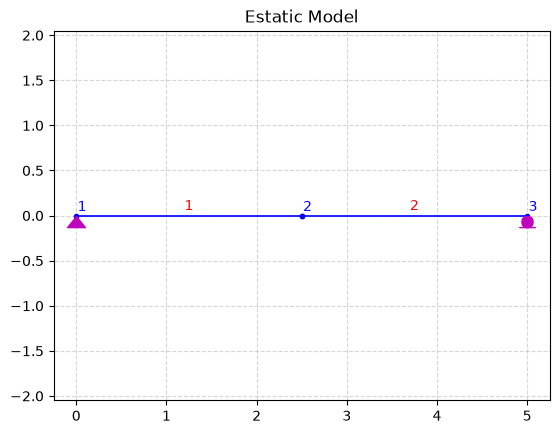

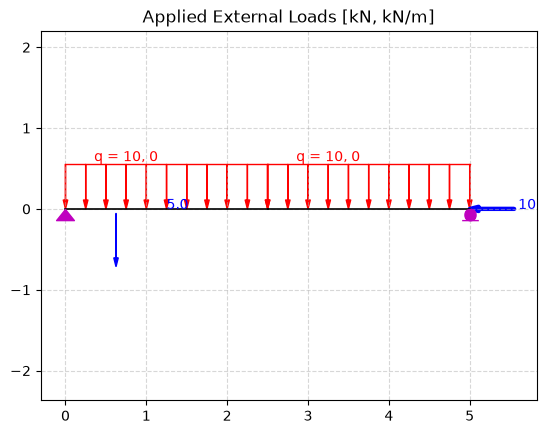

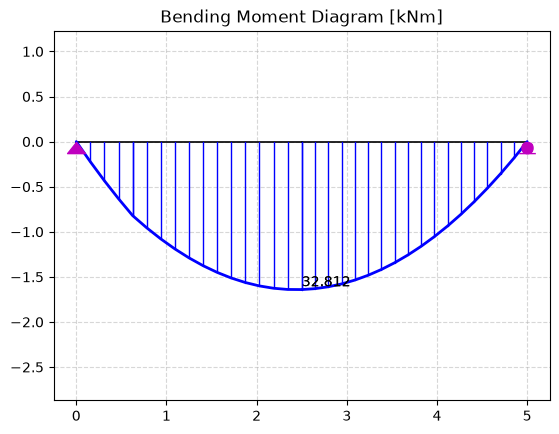

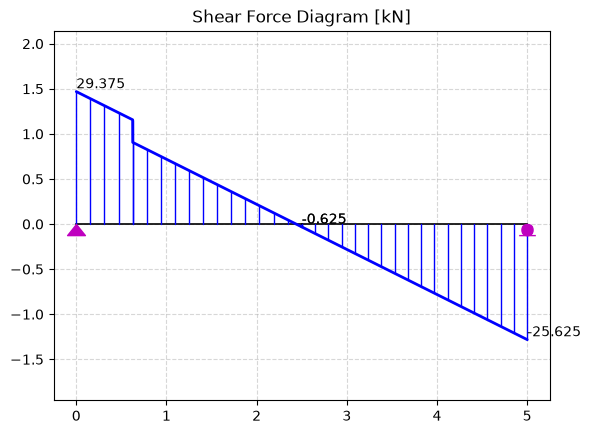

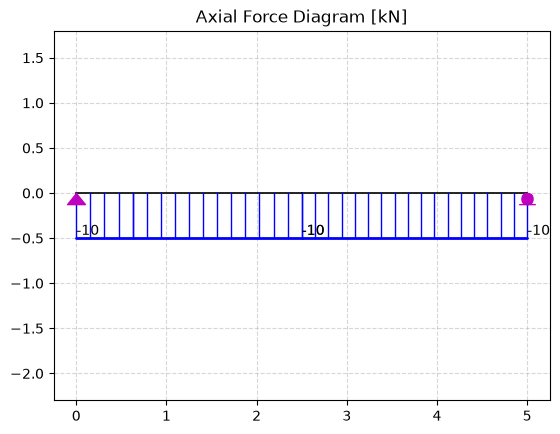

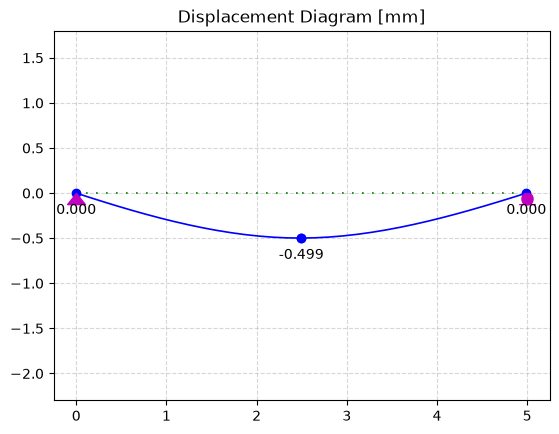

In [ ]:
import openseespy.opensees as ops
import matplotlib.pyplot as plt
import opsvis as opsv

ops.wipe()

# MODEL 
ops.model('basic', '-ndm', 2, '-ndf', 3)

# NODES
L = 5 # m

ops.node(1, 0.0, 0.0)
ops.node(2, L/2, 0.0)
ops.node(3,L,0.0)

# SUPPORTS
"Syntax: `ops.fix(node_tag, UX, UY, RZ)` "
ops.fix(1, 1, 1, 0) 
ops.fix(3, 0, 1, 0) 

E = 32e6          # kN/m2  (32 GPa)
A = 0.3 * 0.6     # m2     
I = 0.3 * 0.6**3 / 12  # m4

# ELEMENTS 
" Syntax: ops.geomTransf(type, transf_tag)"
ops.geomTransf('Linear', 1) # 'Linear' ,  'PDelta' , 'Corotational'
 

" Syntax: ops.element('elasticBeamColumn', eleTag, iNode, jNode, A, E, I, transfTag)"
ops.element('elasticBeamColumn', 1, 1, 2, A, E, I, 1)
ops.element('elasticBeamColumn', 2, 2, 3, A, E, I, 1)

# LOADING
ops.timeSeries('Linear', 1)
ops.pattern('Plain', 1, 1)


# POINT LOAD  
"Syntax (Point load at x/L): `ops.eleLoad('-ele', *eleTags, '-type', '-beamPoint', Py, xL, <Px>)"
ops.eleLoad('-ele', 1, '-type', '-beamPoint', -5.0, 0.25)

# NODE LOAD
"ops.load(nodeTag, Fx, Fy, Mz)"
P = -10 
ops.load(3,P,0,0)

# DISTRIBUTED LOAD 
"ops.eleLoad('-ele', *eleTags, '-type', '-beamUniform', WyI, WyJ, <WxI, WxJ>)"
ops.eleLoad('-ele', 1,2, '-type', '-beamUniform', -10.0)

# ANALYSIS
ops.system('BandGeneral')  # 'BandGeneral' or 'BandSPD'
ops.numberer('RCM')
ops.constraints('Plain') # 'Plain' or 'Transformation' with rigid links, settlements.
ops.integrator('LoadControl', 1.0)
ops.algorithm('Linear') # 'Linear' or 'Newton' for nonlinear problems.
ops.analysis('Static')
ops.analyze(1) # 1 step

# RESULTS
ops.reactions()
print("\n--- REACTIONS [kN, kNm] ---")
for n in (1,2,3):
    rx, ry, rm = ops.nodeReaction(n)
    print(f"Node {n}: Rx = {rx:.2f} kN, Ry = {ry:.2f} kN, M = {rm:.2f} kNm")

print("\n--- DISPLACEMENTS [mm, rad] ---")
for n in (1,2,3):
    ux, uy, rz = ops.nodeDisp(n)
    print(f"Node {n}: ux = {ux*1000:.3f} mm, uy = {uy*1000:.3f} mm, rz = {rz:.6f} rad")

# MODEL PLOT
opsv.plot_model(node_labels=1, element_labels=1)
plt.title("Estatic Model")
plt.axis("equal") # 'equal', 'scaled', 'off'
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# LOAD PLOT
opsv.plot_load(node_supports=True)
plt.title("Applied External Loads [kN, kN/m]")
plt.axis("equal") # 'equal', 'scaled', 'off'
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# DISPLACEMENT DIAGRAM
sfac = 1000
opsv.plot_defo(sfac=sfac, endDispFlag=1, fmt_nodes={'color': 'blue', 'linestyle': 'None', 'marker': 'o', 'markersize': 6})
for n in ops.getNodeTags():
    x, y = ops.nodeCoord(n)
    ux, uy, rz = ops.nodeDisp(n)
    plt.annotate(f"{uy*1000:.3f}", (x + ux*sfac, y + uy*sfac), textcoords="offset points", xytext=(0, -15), ha="center")
plt.title(f"Displacement Diagram [mm]")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# BENDING MOMENT DIAGRAM
opsv.section_force_diagram_2d('M', sfac=0.05)
plt.title("Bending Moment Diagram [kNm]")
plt.axis("equal") # 'equal', 'scaled', 'off'
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# SHEAR FORCE DIAGRAM
opsv.section_force_diagram_2d('V', sfac=0.05)
plt.title("Shear Force Diagram [kN]")

plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# AXIAL FORCE DIAGRAM
opsv.section_force_diagram_2d('N', sfac=0.05)
plt.title("Axial Force Diagram [kN]")

plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


